# 01 · Análise exploratória das avaliações (Olist)

Objetivo: entender o conteúdo textual das avaliações para fundamentar as decisões de
**seleção**, **limpeza** e **tratamento de ausentes** da base de conhecimento.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 200)

In [2]:
reviews = pd.read_csv(ROOT / "data/raw/olist_order_reviews_dataset.csv", encoding="utf-8")
print(reviews.shape)
reviews.head()

(99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa,2018-03-01 00:00:00,2018-03-02 10:26:53


## Valores ausentes

In [3]:
missing = reviews.isna().mean().sort_values(ascending=False).rename("% ausente") * 100
missing.round(1).to_frame()

,% ausente
review_comment_title,88.3
review_comment_message,58.7
review_id,0.0
review_score,0.0
order_id,0.0
review_creation_date,0.0
review_answer_timestamp,0.0


## Notas: todas as avaliações vs. avaliações com comentário

In [4]:
has_text = reviews["review_comment_message"].notna() | reviews["review_comment_title"].notna()
dist = pd.DataFrame({
    "todas": reviews["review_score"].value_counts().sort_index(),
    "com texto": reviews.loc[has_text, "review_score"].value_counts().sort_index(),
})
dist["% com texto"] = (dist["com texto"] / dist["todas"] * 100).round(1)
dist

,todas,com texto,% com texto
review_score,,,
1,11424,8829,77.3
2,3151,2165,68.7
3,8179,3644,44.6
4,19142,6278,32.8
5,57328,21790,38.0


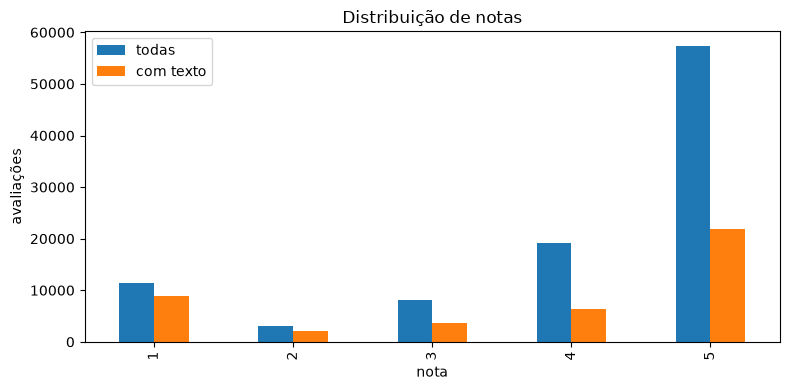

In [5]:
dist[["todas", "com texto"]].plot.bar(figsize=(8, 4), title="Distribuição de notas")
plt.xlabel("nota"); plt.ylabel("avaliações"); plt.tight_layout()

**Leitura:** clientes insatisfeitos comentam proporcionalmente muito mais
(~77% das notas 1 têm texto, contra ~36% das notas 5). A base de conhecimento terá,
portanto, mais peso de reclamações do que a base total, e isso precisa ser dito ao
interpretar frequências.

## Tamanho dos textos

count    40977.0
mean        68.6
std         53.8
min          1.0
25%         28.0
50%         53.0
75%         95.0
max        208.0
Name: review_comment_message, dtype: float64


<Axes: title={'center': 'Caracteres por comentário'}, ylabel='Frequency'>

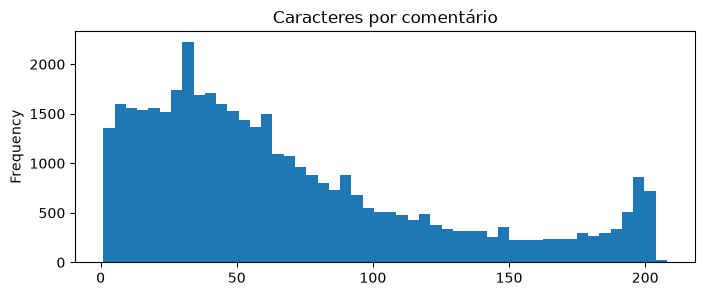

In [6]:
lengths = reviews["review_comment_message"].dropna().str.len()
print(lengths.describe().round(1))
lengths.plot.hist(bins=50, figsize=(8, 3), title="Caracteres por comentário")

**Leitura:** textos muito curtos (mediana ~53 caracteres, máximo ~210). Não há necessidade de
*chunking*: cada avaliação vira um documento.

## Duplicidades

In [7]:
dup_ids = reviews["review_id"].duplicated().sum()
print("review_id repetidos:", dup_ids)
reviews[reviews["review_id"].duplicated(keep=False)].sort_values("review_id").head(6)

review_id repetidos: 814


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com atraso de mais de 15 dias do previsto. Preciso que seja trocado.",2018-03-07 00:00:00,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com atraso de mais de 15 dias do previsto. Preciso que seja trocado.",2018-03-07 00:00:00,2018-03-20 18:08:23
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornecedor sem os parafusos de fixação das partes.,2018-03-07 00:00:00,2018-03-08 03:00:53
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornecedor sem os parafusos de fixação das partes.,2018-03-07 00:00:00,2018-03-08 03:00:53


In [8]:
top_texts = reviews["review_comment_message"].dropna().str.strip().str.lower().value_counts().head(15)
top_texts

review_comment_message
muito bom               472
bom                     342
recomendo               234
otimo                   227
ótimo                   197
excelente               158
ok                      149
tudo ok                  93
boa                      91
ótimo produto            81
gostei                   65
não recebi o produto     65
muito bom.               55
tudo certo               52
.                        52
Name: count, dtype: int64

**Leitura:**
- o mesmo `review_id` aparece em pedidos diferentes (mesma avaliação replicada) → deduplicar por `review_id`;
- muitos textos idênticos e genéricos ("muito bom", "recebi o produto") → colapsar na **seleção de evidências**
  (não no índice), preservando a contagem de repetições.

## Amostras por nota

In [9]:
for score in [1, 3, 5]:
    print(f"--- nota {score}")
    for t in reviews.query("review_score == @score")["review_comment_message"].dropna().sample(5, random_state=0):
        print(" •", t)

--- nota 1
 • nao posso avaliar o produto nao foi entregue
preciso de uma posiçao
 • Não gostei, pois não chegou devido alguns problemas. 
Quero meu dinheiro de volta.
 • Não cumpriu o prazo de entrega!
 • PRODUTO COM AS ESPECIFICAÇÕES DIFERENTES DO ANUNCIADO. 80% ALGODÃO AO INVÉS DE 100% COMO DIZIA NO ANUNCIO
 • Comprei 3 unidades do produto vieram 2 unidades que não corresponde com o que comprei. Devido a minha opinião é negativa com relação a esse vendedor pois não não cumpriu com o prometido na venda.
--- nota 3
 • Comprei o copo cristalino e chegou o leitoso. Serve, mas desagradou-me por ser de qualidade inferior.
 • nota 10
 • Não tenho como avaliar pois ainda não recebi o produto.
 • Achei um pouco demorado a entrega
 • Produto entregue em mãos,lindo e original.Desagradou o fato de cobrar taxa de entrega rápida 10 dias e não cumprir com o combinado.Quero reembolso da taxa extra.Não se vende o que não têm. 
--- nota 5
 • Recebi antes do prazo, muito rápio.
 • O produto foi exatam